# Task 28: Decision Tree from Scratch

## Objective
To implement a Decision Tree classifier using recursive splitting
and Gini impurity. The model will be evaluated and compared with
Logistic Regression using the same train-test split.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart_final_cleaned.csv")

df = df.dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df.head())
print("\nTarget distribution:")
print(df["target"].value_counts())

Dataset shape: (302, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [11]:
if "target" not in df.columns:
    raise ValueError("Dataset must contain a 'target' column.")

feature_columns = [
    col for col in df.select_dtypes(include=["number"]).columns
    if col != "target"
]

X = df[feature_columns].to_numpy(dtype=float)
y_original = df["target"].to_numpy()

classes = np.unique(y_original)

if len(classes) != 2:
    raise ValueError("This notebook expects a binary target.")

# Map the two target classes to 0 and 1
y = (y_original == classes[1]).astype(int)


def manual_stratified_split(X, y, train_ratio=0.8, random_seed=42):
    rng = np.random.default_rng(random_seed)

    train_indices = []
    test_indices = []

    for target_value in np.unique(y):
        class_indices = np.where(y == target_value)[0].copy()
        rng.shuffle(class_indices)

        split_index = int(len(class_indices) * train_ratio)

        train_indices.extend(class_indices[:split_index])
        test_indices.extend(class_indices[split_index:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


X_train, X_test, y_train, y_test = manual_stratified_split(X, y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training class proportions:", np.unique(y_train, return_counts=True))
print("Testing class proportions:", np.unique(y_test, return_counts=True))

Training set: (241, 13)
Testing set: (61, 13)
Training class proportions: (array([0, 1]), array([110, 131]))
Testing class proportions: (array([0, 1]), array([28, 33]))


## Gini Impurity

Gini impurity measures how mixed the target classes are in a node.

Gini = 1 - sum(p_i ** 2)

The best split is the one that produces the largest reduction in
weighted Gini impurity.

In [12]:
def manual_gini(y_values):
    if len(y_values) == 0:
        return 0

    counts = {}

    for label in y_values:
        counts[label] = counts.get(label, 0) + 1

    impurity = 1.0

    for count in counts.values():
        probability = count / len(y_values)
        impurity -= probability ** 2

    return impurity


def manual_entropy(y_values):
    if len(y_values) == 0:
        return 0

    counts = {}

    for label in y_values:
        counts[label] = counts.get(label, 0) + 1

    entropy = 0.0

    for count in counts.values():
        probability = count / len(y_values)
        entropy -= probability * np.log2(probability)

    return entropy

In [13]:
def find_best_split(X, y, criterion="gini", min_samples_split=10):
    n_samples, n_features = X.shape

    if n_samples < min_samples_split:
        return None

    impurity_function = (
        manual_gini if criterion == "gini" else manual_entropy
    )

    parent_impurity = impurity_function(y)
    best_gain = 0
    best_split = None

    for feature_index in range(n_features):
        unique_values = np.unique(X[:, feature_index])

        if len(unique_values) < 2:
            continue

        thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2

        for threshold in thresholds:
            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            if (
                np.sum(left_mask) < 1
                or np.sum(right_mask) < 1
            ):
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_impurity = (
                len(y_left) / n_samples
                * impurity_function(y_left)
                + len(y_right) / n_samples
                * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_split = {
                    "feature_index": feature_index,
                    "threshold": float(threshold),
                    "gain": float(gain),
                    "left_mask": left_mask,
                    "right_mask": right_mask
                }

    return best_split

In [14]:
def build_tree(
    X,
    y,
    feature_names,
    depth=0,
    max_depth=4,
    min_samples_split=10,
    criterion="gini"
):
    class_labels, counts = np.unique(y, return_counts=True)
    majority_class = int(class_labels[np.argmax(counts)])

    # Stop if the node is pure or depth limit is reached
    if (
        len(class_labels) == 1
        or depth >= max_depth
        or len(y) < min_samples_split
    ):
        return {
            "leaf": True,
            "prediction": majority_class,
            "samples": len(y)
        }

    split = find_best_split(
        X,
        y,
        criterion=criterion,
        min_samples_split=min_samples_split
    )

    if split is None or split["gain"] <= 0:
        return {
            "leaf": True,
            "prediction": majority_class,
            "samples": len(y)
        }

    left_mask = split["left_mask"]
    right_mask = split["right_mask"]

    left_tree = build_tree(
        X[left_mask],
        y[left_mask],
        feature_names,
        depth + 1,
        max_depth,
        min_samples_split,
        criterion
    )

    right_tree = build_tree(
        X[right_mask],
        y[right_mask],
        feature_names,
        depth + 1,
        max_depth,
        min_samples_split,
        criterion
    )

    return {
        "leaf": False,
        "feature_index": split["feature_index"],
        "feature": feature_names[split["feature_index"]],
        "threshold": split["threshold"],
        "gain": split["gain"],
        "samples": len(y),
        "left": left_tree,
        "right": right_tree
    }

In [15]:
tree = build_tree(
    X_train,
    y_train,
    feature_columns,
    max_depth=4,
    min_samples_split=10,
    criterion="gini"
)


def print_tree(node, depth=0):
    indent = "  " * depth

    if node["leaf"]:
        print(
            f"{indent}Leaf: class={node['prediction']}, "
            f"samples={node['samples']}"
        )
        return

    print(
        f"{indent}{node['feature']} <= {node['threshold']:.3f} "
        f"(gain={node['gain']:.4f})"
    )

    print_tree(node["left"], depth + 1)
    print_tree(node["right"], depth + 1)


print_tree(tree)

thal <= 2.500 (gain=0.1235)
  ca <= 0.500 (gain=0.0868)
    oldpeak <= 2.600 (gain=0.0359)
      age <= 57.500 (gain=0.0177)
        Leaf: class=1, samples=68
        Leaf: class=1, samples=30
      Leaf: class=0, samples=6
    cp <= 0.500 (gain=0.1858)
      sex <= 0.500 (gain=0.0562)
        Leaf: class=0, samples=5
        Leaf: class=0, samples=17
      age <= 55.000 (gain=0.0894)
        Leaf: class=1, samples=13
        Leaf: class=0, samples=14
  cp <= 0.500 (gain=0.0700)
    oldpeak <= 0.450 (gain=0.0386)
      age <= 62.500 (gain=0.1350)
        Leaf: class=0, samples=14
        Leaf: class=1, samples=2
      Leaf: class=0, samples=43
    oldpeak <= 1.100 (gain=0.1001)
      trestbps <= 151.000 (gain=0.2783)
        Leaf: class=1, samples=11
        Leaf: class=0, samples=3
      cp <= 2.500 (gain=0.2133)
        Leaf: class=0, samples=9
        Leaf: class=1, samples=6


In [16]:
def predict_one(node, row):
    if node["leaf"]:
        return node["prediction"]

    feature_index = node["feature_index"]
    threshold = node["threshold"]

    if row[feature_index] <= threshold:
        return predict_one(node["left"], row)

    return predict_one(node["right"], row)


def predict_tree(tree, X):
    return np.array([
        predict_one(tree, row)
        for row in X
    ])


y_pred_tree = predict_tree(tree, X_test)

print("Actual labels:    ", y_test)
print("Predicted labels: ", y_pred_tree)

Actual labels:     [0 1 0 1 0 0 1 1 1 1 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 1 1 1 0 1 1 0
 1 0 1 0 0 0 1 1 1 1 1 1 0 0 1 0 0 1 1 1 0 0 1 1]
Predicted labels:  [0 1 1 0 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 1 1 0
 1 0 0 0 0 0 1 0 1 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0]


In [17]:
def manual_accuracy(y_true, y_pred):
    if len(y_true) == 0:
        return 0

    correct = 0

    for actual, predicted in zip(y_true, y_pred):
        if actual == predicted:
            correct += 1

    return correct / len(y_true)


tree_accuracy = manual_accuracy(y_test, y_pred_tree)

print(f"Decision Tree Accuracy: {tree_accuracy:.4f}")

Decision Tree Accuracy: 0.7049


In [18]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Scale features using training data only
means = np.mean(X_train, axis=0)
stds = np.std(X_train, axis=0)
stds[stds == 0] = 1

X_train_scaled = (X_train - means) / stds
X_test_scaled = (X_test - means) / stds


def train_logistic_regression(X, y, learning_rate=0.01, epochs=2000):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    for _ in range(epochs):
        probabilities = sigmoid(X @ weights + bias)
        error = probabilities - y

        dw = (X.T @ error) / n_samples
        db = np.sum(error) / n_samples

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias


weights, bias = train_logistic_regression(
    X_train_scaled,
    y_train
)

logistic_probabilities = sigmoid(X_test_scaled @ weights + bias)
y_pred_logistic = (logistic_probabilities >= 0.5).astype(int)

logistic_accuracy = manual_accuracy(y_test, y_pred_logistic)

print(f"Decision Tree Accuracy:      {tree_accuracy:.4f}")
print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")

Decision Tree Accuracy:      0.7049
Logistic Regression Accuracy: 0.8197


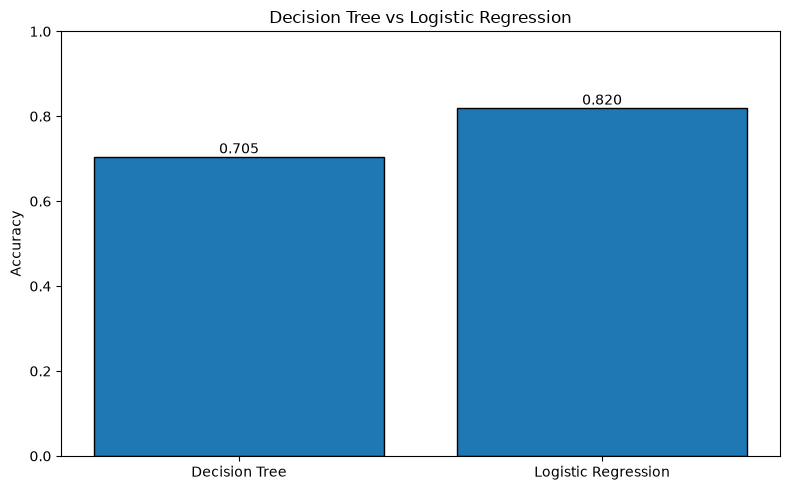

In [19]:
model_names = ["Decision Tree", "Logistic Regression"]
accuracies = [tree_accuracy, logistic_accuracy]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    model_names,
    accuracies,
    edgecolor="black"
)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Decision Tree vs Logistic Regression")

for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## Conclusion

A Decision Tree classifier was implemented from scratch using recursive
splitting and Gini impurity. The tree was trained on the training set and
evaluated on the held-out test set. A manually implemented Logistic
Regression model was also trained using the same split for comparison.

The models may differ in accuracy and decision paths because a Decision
Tree learns threshold-based rules while Logistic Regression learns a
linear decision boundary. Accuracy alone does not fully describe model
quality, and this educational experiment is not intended for clinical use.